# Multimodal analysis of cfDNA using modalibpy
---

* [Loading the data](#loading)
* [Exploratory data analysis](#eda)
* [Multimodal heatmaps](#multimodal-heatmap)
* [Preprocessing and kernel matrices](#preprocessing)
* [t-SNE/kPCA](#tsne)
* [Supervised learning](#supervised-learning)

<h2>Requirements</h2>

MetDecode should be installed. It can be found at [https://github.com/JorisVermeeschLab/MetDecode](https://github.com/JorisVermeeschLab/MetDecode).

Importing `modalibpy` should work. That means, the `modalibpy` folder should either be at the same location as this notebook, or the path to it should be added, for example by running this code cell:.

In [ ]:
import sys
sys.path.append('/lustre1/project/stg_00019/research/Antoine/MODaLiB')

Before running this notebook, make sure that the following files exist, relative to where you run the notebook:

- The `/outputs/downsampled-50kb-noXY`, `/outputs/downsampled-methmarkerdbcolorectal-noXY` and `/outputs/metdecode-noXY` sub-folders, which should contain each a `.npz` file for each sample. The filename should be the GC code, followed by the `.npz` extension. Each `.npz` file should contain not only the arrays computed using the `extract_features` function, but also `OT-R1`, `OT-R2`, `OB-R1` and `OB-R2` arrays containing the methylation ratios for each base position on reads, as outputed by the MBias command from MethylDackel. If one of these 4 arrays is missing, then the jaggedness feature extractor will not work.
- The EM-Seq metadata file `Metadata_EMseqsamples.xlsx`.
- The list of DMRs `regions/metdecode/dmrs.csv` used to produce the content of `/outputs/metdecode-noXY` using the `extract_features` function.
- The methylation atlas `regions/metdecode/atlas.tsv` from MetDecode, which contains the same DMRs as in `regions/metdecode/dmrs.csv`.

<h2>Import dependencies</h2>

In [1]:
%load_ext autoreload

In [2]:
%autoreload 2

In [40]:
import os
from typing import Tuple, Set, List, Dict

import numpy as np
import seaborn
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler, RobustScaler
from sklearn.decomposition import KernelPCA
from sklearn.manifold import TSNE

from modalibpy.dataset import Dataset
from modalibpy.modalities import Modalities
from modalibpy.pipeline.mkl import MultipleKernelLearning
from modalibpy.stages import Annotation
from modalibpy.end_motifs import EndMotifHistograms, uint8_motif_to_str
from modalibpy.modalities.jaggedness import JaggednessModality
from modalibpy.modalities.end_motif_frequency import EndMotifFrequencyModality
from modalibpy.modalities.coverage import CoverageModality
from modalibpy.modalities.cpg_methylation import CpGMethylationModality
from modalibpy.modalities.nucleosome_positioning import NucleosomePositioningModality
from modalibpy.modalities.frag_length_counts import FragLengthCountModality
from modalibpy.modalities.cell_type_deconvolution import CellTypeDeconvolutionModality
from modalibpy.modalities.long_frag_ratio import LongFragmentRatioModality

<h1 id="loading">Loading the data</h1> <a class="anchor" id="loading"></a>

In [6]:
# Location of important files
METADATA_FILEPATH = 'Metadata_EMseqsamples.xlsx'
METDECODE_DMR_FILEPATH = 'regions/metdecode/dmrs.csv'
METDECODE_ATLAS_FILEPATH = 'regions/metdecode/atlas.tsv'

# Location of the NumPy archives
DATA_PATH = 'outputs'

# Sample identifiers = filenames (without extensions)
DATASET_TRAIN = ['GC114131', 'GC114133', 'GC114135', 'GC114136', 'GC114137', 'GC114138', 'GC114139', 'GC114140', 'GC114141', 'GC114142', 'GC114183', 'GC114185', 'GC114186', 'GC118465', 'GC118466', 'GC118470', 'GC118471', 'GC118472', 'GC118473', 'GC118474', 'GC118475', 'GC118476', 'GC118480', 'GC118481', 'GC118482', 'GC118484', 'GC118485', 'GC118486', 'GC118487', 'GC118489', 'GC118490', 'GC118491', 'GC118492', 'GC118493', 'GC118494', 'GC118495', 'GC118496', 'GC118497', 'GC118499', 'GC119341', 'GC119343', 'GC119344', 'GC119358', 'GC119360', 'GC119361', 'GC119367', 'GC119369', 'GC119370', 'GC119373', 'GC119375', 'GC119376', 'GC119377', 'GC119381', 'GC119382', 'GC119383', 'GC119384', 'GC119385', 'GC119388', 'GC119389', 'GC119390', 'GC119393', 'GC119394', 'GC119395', 'GC119396', 'GC119397', 'GC119398', 'GC119399', 'GC119401', 'GC119404', 'GC119407', 'GC119408', 'GC119409', 'GC119410', 'GC119411', 'GC119412', 'GC119414', 'GC119415', 'GC119416', 'GC119417', 'GC119419', 'GC119420', 'GC119421', 'GC119423', 'GC119425', 'GC119427', 'GC119429', 'GC119430', 'GC121332', 'GC121334', 'GC121337', 'GC121339', 'GC121343', 'GC121344', 'GC121345', 'GC121346', 'GC121348', 'GC121349', 'GC146664_GAACGGTT-GGAGGAAT', 'GC146664_GGAATGTC-AGGAACAC', 'GC146664_TGGTGAAG-CTTACAGC', 'GC146665_CCAGTATC-AGCGAGAT', 'GC146665_GTAACCGA-AAGACACC', 'GC146665_GTCGTTAC-AGCTAAGC', 'GC146665_TACGGTCT-TCCATTGC', 'GC146665_TCTACGCA-CAATAGCC', 'GC146766_AAGACCGT-GTCGATTG', 'GC146766_CAGGTTCA-ATAACGCC', 'GC146766_TACGGTCT-TCCATTGC', 'GC146766_TACTCCAG-GGTATAGG', 'GC146766_TAGGAGCT-GCCTTAAC', 'GC146766_TCGTCTGA-GTCCTTGA', 'GC146766_TTACCGAC-CGAATACG', 'GC146766_TTCCAGGT-CAGTGCTT', 'GC1003994', 'GC1003995', 'GC1003996', 'GC1003997', 'GC1003998', 'GC1003999', 'GC1004000', 'GC1004001', 'GC1004002', 'GC1004003', 'GC121326', 'GC121327', 'GC121328', 'GC121329', 'GC121330', 'GC137538_ACGAATCC-ATTACCCA', 'GC137539_GTCTGAGT-GACTTGTG', 'GC137540_ATTACCCA-CACTGTAG', 'GC137541_GACTTGTG-GTGCACGA', 'GC137542_TTCAATAG-TCCCACGA', 'GC137543_GTTTGCTC-ACCAACAG', 'GC137544_ACCGGAGT-AAGGAAGG', 'GC137545_CTTGACGA-GCACACAA', 'GC137546_TGTTCGCC-AGGTAGGA', 'GC137547_ACAAGGCA-TCGCGCAA', 'GC137548_CCTGTCAA-ATGGCTGT', 'GC137549_CCATCCGC-AAGGCGTA', 'GC137550_ATGGCTGT-CCTGTCAA', 'GC137551_AAGGCGTA-CCATCCGC', 'GC137552_AGGTAGGA-TGTTCGCC', 'GC137553_TCGCGCAA-ACAAGGCA', 'GC137554_AAGGAAGG-ACCGGAGT', 'GC137555_GCACACAA-CTTGACGA', 'GC137556_TCCCACGA-TTCAATAG', 'GC137557_ACCAACAG-GTTTGCTC', 'GC140036_TTACCGAC-CGAATACG', 'GC140037_TCGTCTGA-GTCCTTGA', 'GC140038_TTCCAGGT-CAGTGCTT', 'GC140039_TACGGTCT-TCCATTGC', 'GC140040_AAGACCGT-GTCGATTG', 'GC140041_CAGGTTCA-ATAACGCC', 'GC140042_TAGGAGCT-GCCTTAAC', 'GC140043_TACTCCAG-GGTATAGG', 'GC140044_AGTGACCT-TCTAGGAG', 'GC140045_AGCCTATC-TGCGTAAC', 'GC140046_TCATCTCC-CTTGCTAG', 'GC140047_CCAGTATC-AGCGAGAT', 'GC140048_TTGCGAGA-TATGGCAC', 'GC140049_GAACGAAG-GAATCACC', 'GC140050_CGAATTGC-GTAAGGTG', 'GC140051_GGAAGAGA-CGAGAGAA', 'GC140053_CTGTACCA-CACAGACT', 'GC140054_GAGAGTAC-TGGAAGCA', 'GC140055_TCTACGCA-CAATAGCC', 'GC140056_GCAATTCC-CTCGAACA', 'GC140057_CTCAGAAG-GGCAAGTT', 'GC140058_GTCCTAAG-AGCTACCA', 'GC140059_GCGTTAGA-CAGCATAC', 'GC146664_AAGACACC-GTAACCGA', 'GC146664_AGCTAAGC-GTCGTTAC', 'GC146664_AGCTACCA-GTCCTAAG', 'GC146664_CAACTCCA-GAATCCGT', 'GC146664_CAATAGCC-TCTACGCA', 'GC146664_CAATGCGA-GACGAACT', 'GC146664_CACAGACT-CTGTACCA', 'GC146664_CAGCATAC-GCGTTAGA', 'GC146664_CCACAACA-GTACCACA', 'GC146664_CGCAACTA-TCGGATTC', 'GC146664_CGTATCTC-CAAGGTAC', 'GC146664_CTCGAACA-GCAATTCC', 'GC146664_CTCGACTT-ATCTGACC', 'GC146664_CTTCACTG-CTTAGGAC', 'GC146664_CTTCGGTT-AACCAGAG', 'GC146664_GATAGCCA-CAACACAG', 'GC146664_GATCTTGC-CATGAGCA', 'GC146664_GGACATCA-TACCTGCA', 'GC146664_GGCAAGTT-CTCAGAAG', 'GC146664_GGTGTACA-AGACGCTA', 'GC146664_GGTTGAAC-TCCACGTT', 'GC146664_GTCATCGT-CCGCTTAA', 'GC146664_TGGAAGCA-GAGAGTAC', 'GC146664_TTACGTGC-AGACCTTG', 'GC146665_ATCTGACC-CTCGACTT', 'GC146665_CAGGTTCA-ATAACGCC', 'GC146665_CATGAGCA-GATCTTGC', 'GC146665_CGAATTGC-GTAAGGTG', 'GC146665_CTCAGAAG-GGCAAGTT', 'GC146665_CTTAGGAC-CTTCACTG', 'GC146665_GAACGAAG-GAATCACC', 'GC146665_GAATCCGT-CAACTCCA', 'GC146665_GCAATTCC-CTCGAACA', 'GC146665_GCGTTAGA-CAGCATAC', 'GC146665_GGAAGAGA-CGAGAGAA', 'GC146665_GTCCTAAG-AGCTACCA', 'GC146665_TACTCCAG-GGTATAGG', 'GC146665_TAGGAGCT-GCCTTAAC', 'GC146665_TTGCGAGA-TATGGCAC']
DATASET_TEST = ['GC116989', 'GC116991', 'GC131878', 'GC131879', 'GC131880', 'GC131881', 'GC131883', 'GC131886', 'GC131888', 'GC131889', 'GC131896', 'GC131899', 'GC131901', 'GC131902', 'GC131905', 'GC131906', 'GC131907', 'GC131908', 'GC131911', 'GC131912', 'GC131913', 'GC131914', 'GC131915', 'GC142057_AGACCTTG-TTACGTGC', 'GC142059_GTAACCGA-AAGACACC', 'GC142061_CATGAGCA-GATCTTGC', 'GC142062_CTTAGGAC-CTTCACTG', 'GC142070_TCCACGTT-GGTTGAAC', 'GC142071_AACCAGAG-CTTCGGTT', 'GC142073_CCTTCCAT-CACGCAAT', 'GC145416_CGAATACG-TTACCGAC', 'GC145417_GTCCTTGA-TCGTCTGA', 'GC145418_CAGTGCTT-TTCCAGGT', 'GC145420_GTCGATTG-AAGACCGT', 'GC145424_TCTAGGAG-AGTGACCT', 'GC145426_CTTGCTAG-TCATCTCC', 'GC145427_AGCGAGAT-CCAGTATC', 'GC145432_CGCAACTA-TCGGATTC', 'GC145434_TGGAAGCA-GAGAGTAC', 'GC145435_CAATAGCC-TCTACGCA', 'GC145436_CTCGAACA-GCAATTCC', 'GC145438_AGCTACCA-GTCCTAAG', 'GC145439_CAGCATAC-GCGTTAGA', 'GC145440_CGTATCTC-CAAGGTAC', 'GC145442_AGCTAAGC-GTCGTTAC', 'GC145444_GTACACCT-TCCTCATG', 'GC145446_CCAGTTGA-GACGTCAT', 'GC145447_GTCATCGT-CCGCTTAA', 'GC145448_CAATGCGA-GACGAACT', 'GC145449_GGTTGAAC-TCCACGTT', 'GC145450_CTTCGGTT-AACCAGAG', 'GC146769_CGAATACG-TTACCGAC', 'GC146769_GCCTTAAC-TAGGAGCT', 'GC146769_GGTATAGG-TACTCCAG', 'GC146769_GTAAGGTG-CGAATTGC', 'GC146769_TGCGTAAC-AGCCTATC', 'GC147297_AAGCGACT-ACGAATCC', 'GC147297_AAGGCGTA-CCATCCGC', 'GC147297_ACAAGGCA-TCGCGCAA', 'GC147297_ACCAACAG-GTTTGCTC', 'GC147297_ACGAATCC-ATTACCCA', 'GC147297_ATTACCCA-CACTGTAG', 'GC147297_CACTGTAG-AAGCGACT', 'GC147297_CCATCCGC-AAGGCGTA', 'GC147297_CCTGTCAA-ATGGCTGT', 'GC147297_GTCTGAGT-GACTTGTG', 'GC147297_TCCCACGA-TTCAATAG', 'GC147297_TCGCGCAA-ACAAGGCA', 'GC147297_TGATAGGC-GTCTGAGT', 'GC147298_ACGAATCC-ATTACCCA', 'GC147298_ATTACCCA-CACTGTAG', 'GC147298_GACTTGTG-GTGCACGA', 'GC112890', 'GC142056_CAAGGTAC-CGTATCTC', 'GC142060_GAATCCGT-CAACTCCA', 'GC142064_TCCTCATG-GTACACCT', 'GC142068_CCGCTTAA-GTCATCGT', 'GC142072_GTCAGTCA-CGGCATTA', 'GC142076_TACCTGCA-GGACATCA', 'GC146328_TTACCGAC-CGAATACG', 'GC146329_TCGTCTGA-GTCCTTGA', 'GC146330_TTCCAGGT-CAGTGCTT', 'GC146331_TACGGTCT-TCCATTGC', 'GC146332_AAGACCGT-GTCGATTG', 'GC146333_CAGGTTCA-ATAACGCC', 'GC146334_TAGGAGCT-GCCTTAAC', 'GC146335_TACTCCAG-GGTATAGG', 'GC146336_AGTGACCT-TCTAGGAG', 'GC146337_AGCCTATC-TGCGTAAC', 'GC146338_TCATCTCC-CTTGCTAG', 'GC146339_CCAGTATC-AGCGAGAT', 'GC146340_TTGCGAGA-TATGGCAC', 'GC146341_GAACGAAG-GAATCACC', 'GC146342_CGAATTGC-GTAAGGTG', 'GC146343_GGAAGAGA-CGAGAGAA', 'GC146344_TCGGATTC-CGCAACTA', 'GC146345_CTGTACCA-CACAGACT', 'GC146346_GAGAGTAC-TGGAAGCA', 'GC146347_TCTACGCA-CAATAGCC', 'GC146348_GCAATTCC-CTCGAACA', 'GC146349_CTCAGAAG-GGCAAGTT', 'GC146350_GTCCTAAG-AGCTACCA', 'GC146351_GCGTTAGA-CAGCATAC', 'GC146352_CAAGGTAC-CGTATCTC', 'GC146353_AGACCTTG-TTACGTGC', 'GC146354_GTCGTTAC-AGCTAAGC', 'GC146355_GTAACCGA-AAGACACC', 'GC146356_GAATCCGT-CAACTCCA', 'GC146357_CATGAGCA-GATCTTGC', 'GC146358_CTTAGGAC-CTTCACTG', 'GC146359_ATCTGACC-CTCGACTT', 'GC146360_TCCTCATG-GTACACCT', 'GC146361_AGGATAGC-CCAAGGTT', 'GC146362_GGAGGAAT-GAACGGTT', 'GC146363_GACGTCAT-CCAGTTGA', 'GC146364_CCGCTTAA-GTCATCGT', 'GC146365_GACGAACT-CAATGCGA', 'GC146366_TCCACGTT-GGTTGAAC', 'GC146367_AACCAGAG-CTTCGGTT', 'GC146368_GTCAGTCA-CGGCATTA', 'GC146369_CCTTCCAT-CACGCAAT', 'GC146370_AGGAACAC-GGAATGTC', 'GC146371_CTTACAGC-TGGTGAAG', 'GC146372_TACCTGCA-GGACATCA', 'GC146373_AGACGCTA-GGTGTACA', 'GC146374_CAACACAG-GATAGCCA', 'GC146375_GTACCACA-CCACAACA', 'GC146376_CGAATACG-TTACCGAC', 'GC146377_GTCCTTGA-TCGTCTGA', 'GC146378_CAGTGCTT-TTCCAGGT', 'GC146379_TCCATTGC-TACGGTCT', 'GC146380_GTCGATTG-AAGACCGT', 'GC146381_ATAACGCC-CAGGTTCA', 'GC146382_GCCTTAAC-TAGGAGCT', 'GC146383_GGTATAGG-TACTCCAG', 'GC146384_TCTAGGAG-AGTGACCT', 'GC146385_TGCGTAAC-AGCCTATC', 'GC146386_CTTGCTAG-TCATCTCC', 'GC146387_AGCGAGAT-CCAGTATC', 'GC146388_TATGGCAC-TTGCGAGA', 'GC146389_GAATCACC-GAACGAAG', 'GC146390_GTAAGGTG-CGAATTGC', 'GC146391_CGAGAGAA-GGAAGAGA', 'GC146769_CGAGAGAA-GGAAGAGA']
DATASET = DATASET_TRAIN + DATASET_TEST

<h2>Define how to assemble a dataset</h2>

In [7]:
def load_dataset(filepaths: List[str]) -> Dataset:

    # Load metadata file
    df = pd.read_excel(METADATA_FILEPATH)

    # Build dictionaries, where keys are GC codes, and values are taken from the metadata file
    annot_dict, batch_dict = {}, {}
    for i in range(len(df)):

        # Get annotation (colorectal cancer subtype, or non-cancer otherwise)
        gc_code = df['GC CODE'][i]
        if isinstance(df['Cancer Type'][i], str) and (df['Cancer Type'][i].lower() == 'colorectal cancer'):   # Colorectal cancer

            # Get cancer sub-type info
            s = ''
            if isinstance(df['Subtype'][i], str):
                s += df['Subtype'][i]
            if isinstance(df['other info'][i], str):
                s += df['other info'][i]

            # Create sample Annotation (used to define labels)
            annot = Annotation(
                True,  # True = cancer = not a control
                df['stage'][i],  # Cancer stage
                s,  # Cancer subtype
                cancer_type='colorectal'  # Cancer type
            )
        else:
            # Create sample Annotation (used to define labels)
            annot = Annotation()  # Non-cancer
        annot_dict[gc_code] = annot

        # Get the run information, will be used for grouping during cross-validation (avoid batch effects)
        batch_dict[gc_code] = df['Run'][i]

    # Get GC codes from the file paths
    gc_codes = [os.path.splitext(os.path.basename(filepath))[0] for filepath in filepaths]
    annotations, batches = [], []
    for gc_code in gc_codes:
        if gc_code not in annot_dict:
            gc_code = gc_code.split('_')[0]
        annotations.append(annot_dict[gc_code])
        batches.append(batch_dict[gc_code])

    # Convert side informations to NumPy arrays
    annotations = np.asarray(annotations, dtype=object)
    batches = np.asarray(batches, dtype=str)
    groups = np.squeeze(LabelEncoder().fit_transform(batches))

    # Create dataset
    return Dataset(filepaths, annotations, groups=groups)


def load_methylation_atlas() -> np.ndarray:

    from metdecode.io import load_input_file
    from metdecode.model import MetDecode

    # Load differentially-methylation regions (this list should be the same as the one used
    # to produce the results stored in the /outputs/metdecode-noXY folder).
    dmrs = []
    with open(METDECODE_DMR_FILEPATH, 'r') as f:
        for line in f:
            elements = line.rstrip().split(',')
            if len(elements) < 3:
                continue
            dmrs.append(f'chr{elements[0]}-{elements[1]}-{elements[2]}')

    # Load methylation atlas (should again be based on the same list of DMRs)
    M_atlas, D_atlas, cell_types, marker_names = load_input_file(METDECODE_ATLAS_FILEPATH)
    cell_types = np.asarray(cell_types, dtype=object)

    # Filter out irrelevant cell types (breast cancer, ovarian cancer and cervical cancer)
    mask = np.asarray([0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1], dtype=bool)
    cell_types = cell_types[mask]
    M_atlas = M_atlas[mask]
    D_atlas = D_atlas[mask]

    # Impute missing values
    marker_dict = {marker_name: i for i, marker_name in enumerate(marker_names)}
    M_atlas, D_atlas = MetDecode.add_pseudo_counts(M_atlas, D_atlas)
    R_atlas = M_atlas / D_atlas

    # Sort the atlas to match the order of DMRs from the DMR list
    R_sorted = []
    for dmr in dmrs:
        k = marker_dict[dmr]
        R_sorted.append(R_atlas[:, k])
    R_atlas = np.asarray(R_sorted).T

    # Return methylation ratios
    return R_atlas


def get_dataset(gc_codes: List[str]) -> Dataset:
    # All modalities are not derived from the same marker lists. However, one dataset is constructed for each modality.
    # Therefore, we need to combine the datasets into a single one.

    # First region list: 50 kb bins
    dataset = load_dataset([os.path.join(DATA_PATH, 'downsampled-50kb-noXY', f'{gc_code}.npz') for gc_code in gc_codes])

    # Second region list: DMRs from MethMarkerDB
    dataset_meth = load_dataset([os.path.join(DATA_PATH, 'downsampled-methmarkerdbcolorectal-noXY', f'{gc_code}.npz') for gc_code in gc_codes])
    for key in ['CpG Methylation (first moment)', 'CpG Methylation (second moment)', 'CHG Methylation (first moment)', 'CHH Methylation (first moment)', 'CpG count']:
        dataset.data[key] = dataset_meth.data[key]  # We copy only information related to methylation

    # Third region list: DMRs from MetDecode
    dataset_deconvolution = load_dataset([os.path.join(DATA_PATH, 'metdecode-noXY', f'{gc_code}.npz') for gc_code in gc_codes])
    dataset.data['CpG Methylation (deconvolution, cfDNA)'] = dataset_deconvolution.data['CpG Methylation (first moment)']
    dataset.data['CpG count (deconvolution, cfDNA)'] = dataset_deconvolution.data['CpG count']
    dataset.data['CpG Methylation (deconvolution, reference)'] = load_methylation_atlas()  # Add methylation atlas
    
    return dataset

<h1 id="eda">Exploratory data analysis</h1> <a class="anchor" id="eda"></a>

In [9]:
# Load all samples
dataset = get_dataset(DATASET)

In [10]:
# Transform annotations into integers (0 for control, 1 for cancer)
annotations = dataset.annotations
y = np.asarray([annot.is_cancer for annot in annotations], dtype=int)

# An alternative is to have a different value for each cancer stage: 0 for control, 1 for stage 0, 2 for stage 1, etc.:
#y = np.asarray([np.nan_to_num(float(annot)) + 1 for annot in annotations], dtype=int)
# Indeed, annot is an instance of the Annotation class, for which float conversion is defined, and gives the cancer stage.
# When the annotation is a control, float(annot) gives np.nan.

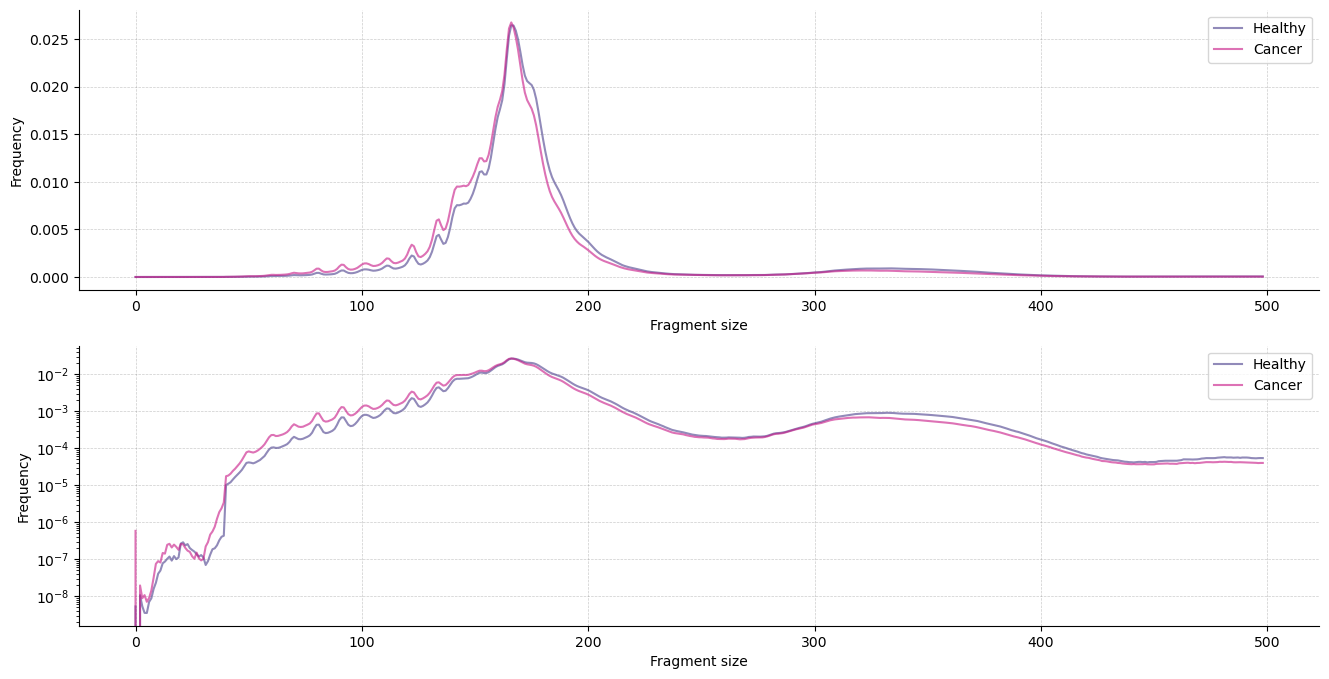

In [11]:
# Fragment size distributions (excluding sizes of 500 bp or more)
X = dataset.data['Fragment length counts'][:, :-1]
X = X / np.sum(X, axis=1)[:, np.newaxis]

# Average across all the controls
x0 = np.mean(X[y == 0, :], axis=0)
# As an alternative, you can select a single sample. For example, the first one:
#x0 = X[y == 0, :][0, :]

# Average across all cancer cases
x1 = np.mean(X[y == 1, :], axis=0)

# Show distribution in linear scale
plt.figure(figsize=(16, 8))
ax = plt.subplot(2, 1, 1)
ax.plot(x0, color='darkslateblue', alpha=0.6, label='Healthy')
ax.plot(x1, color='mediumvioletred', alpha=0.6, label='Cancer')
ax.set_xlabel('Fragment size')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)

# Show distribution in log scale
ax = plt.subplot(2, 1, 2)
ax.plot(x0, color='darkslateblue', alpha=0.6, label='Healthy')
ax.plot(x1, color='mediumvioletred', alpha=0.6, label='Cancer')
ax.set_xlabel('Fragment size')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.set_yscale('log')
plt.show()

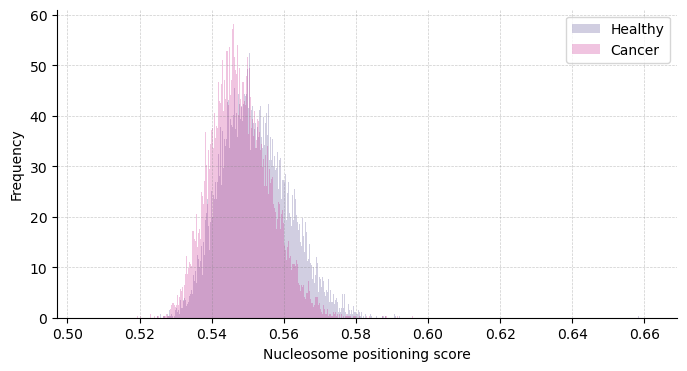

In [23]:
X = dataset.data['Nucleosome positioning']

# Average across controls
x0 = np.mean(X[y == 0, :], axis=0)
x0 = x0[x0 != 0.5] # Remove regions with missing values (0.5 is the default score)

# Average across cancer cases
x1 = np.mean(X[y == 1, :], axis=0)
x1 = x1[x1 != 0.5] # Remove regions with missing values (0.5 is the default score)

# Show distribution of per-bin nucleosome scores
plt.figure(figsize=(8, 4))
ax = plt.subplot(1, 1, 1)
ax.hist(x0, color='darkslateblue', alpha=0.25, label='Healthy', bins=3000, density=True)
ax.hist(x1, color='mediumvioletred', alpha=0.25, label='Cancer', bins=3000, density=True)
ax.set_xlabel('Nucleosome positioning score')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
#ax.set_xlim([0.49, 0.62])
plt.show()

C:\Users\antoi\AppData\Local\Temp\ipykernel_14612\2782353694.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Healthy', 'Cancer'])


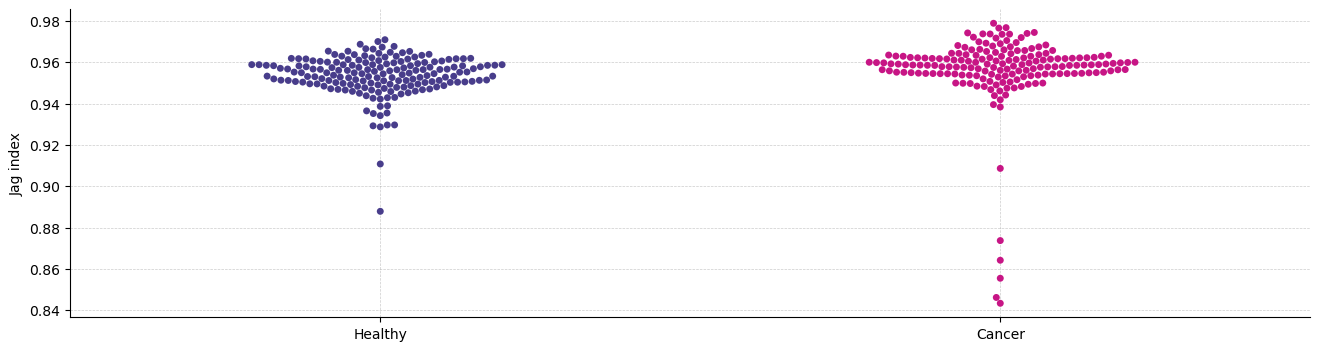

In [19]:
from modalibpy.modalities.jaggedness import JaggednessModality

jag_indexes = JaggednessModality.compute_jaggedness(dataset.data)

plt.figure(figsize=(16, 4))
ax = plt.subplot(1, 1, 1)
seaborn.swarmplot([jag_indexes[y == 0], jag_indexes[y == 1]], ax=ax, palette=['darkslateblue', 'mediumvioletred'])
ax.set_ylabel('Jag index')
ax.set_xticklabels(['Healthy', 'Cancer'])
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
plt.show()

In [27]:
from modalibpy.end_motifs import EndMotifHistograms

emh = EndMotifHistograms(dataset.data['End-motif probability (5 prime)'])
print('ACCT', emh['ACCT'][0])  # Frequency of ACCT motif in first sample
print('CCNN', emh['CCNN'][1])  # Frequency of CCAA, CCAT, CCAG, etc. motifs in second sample

ACCT 0.005041693928055156
CCNN 0.09989515293512795


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


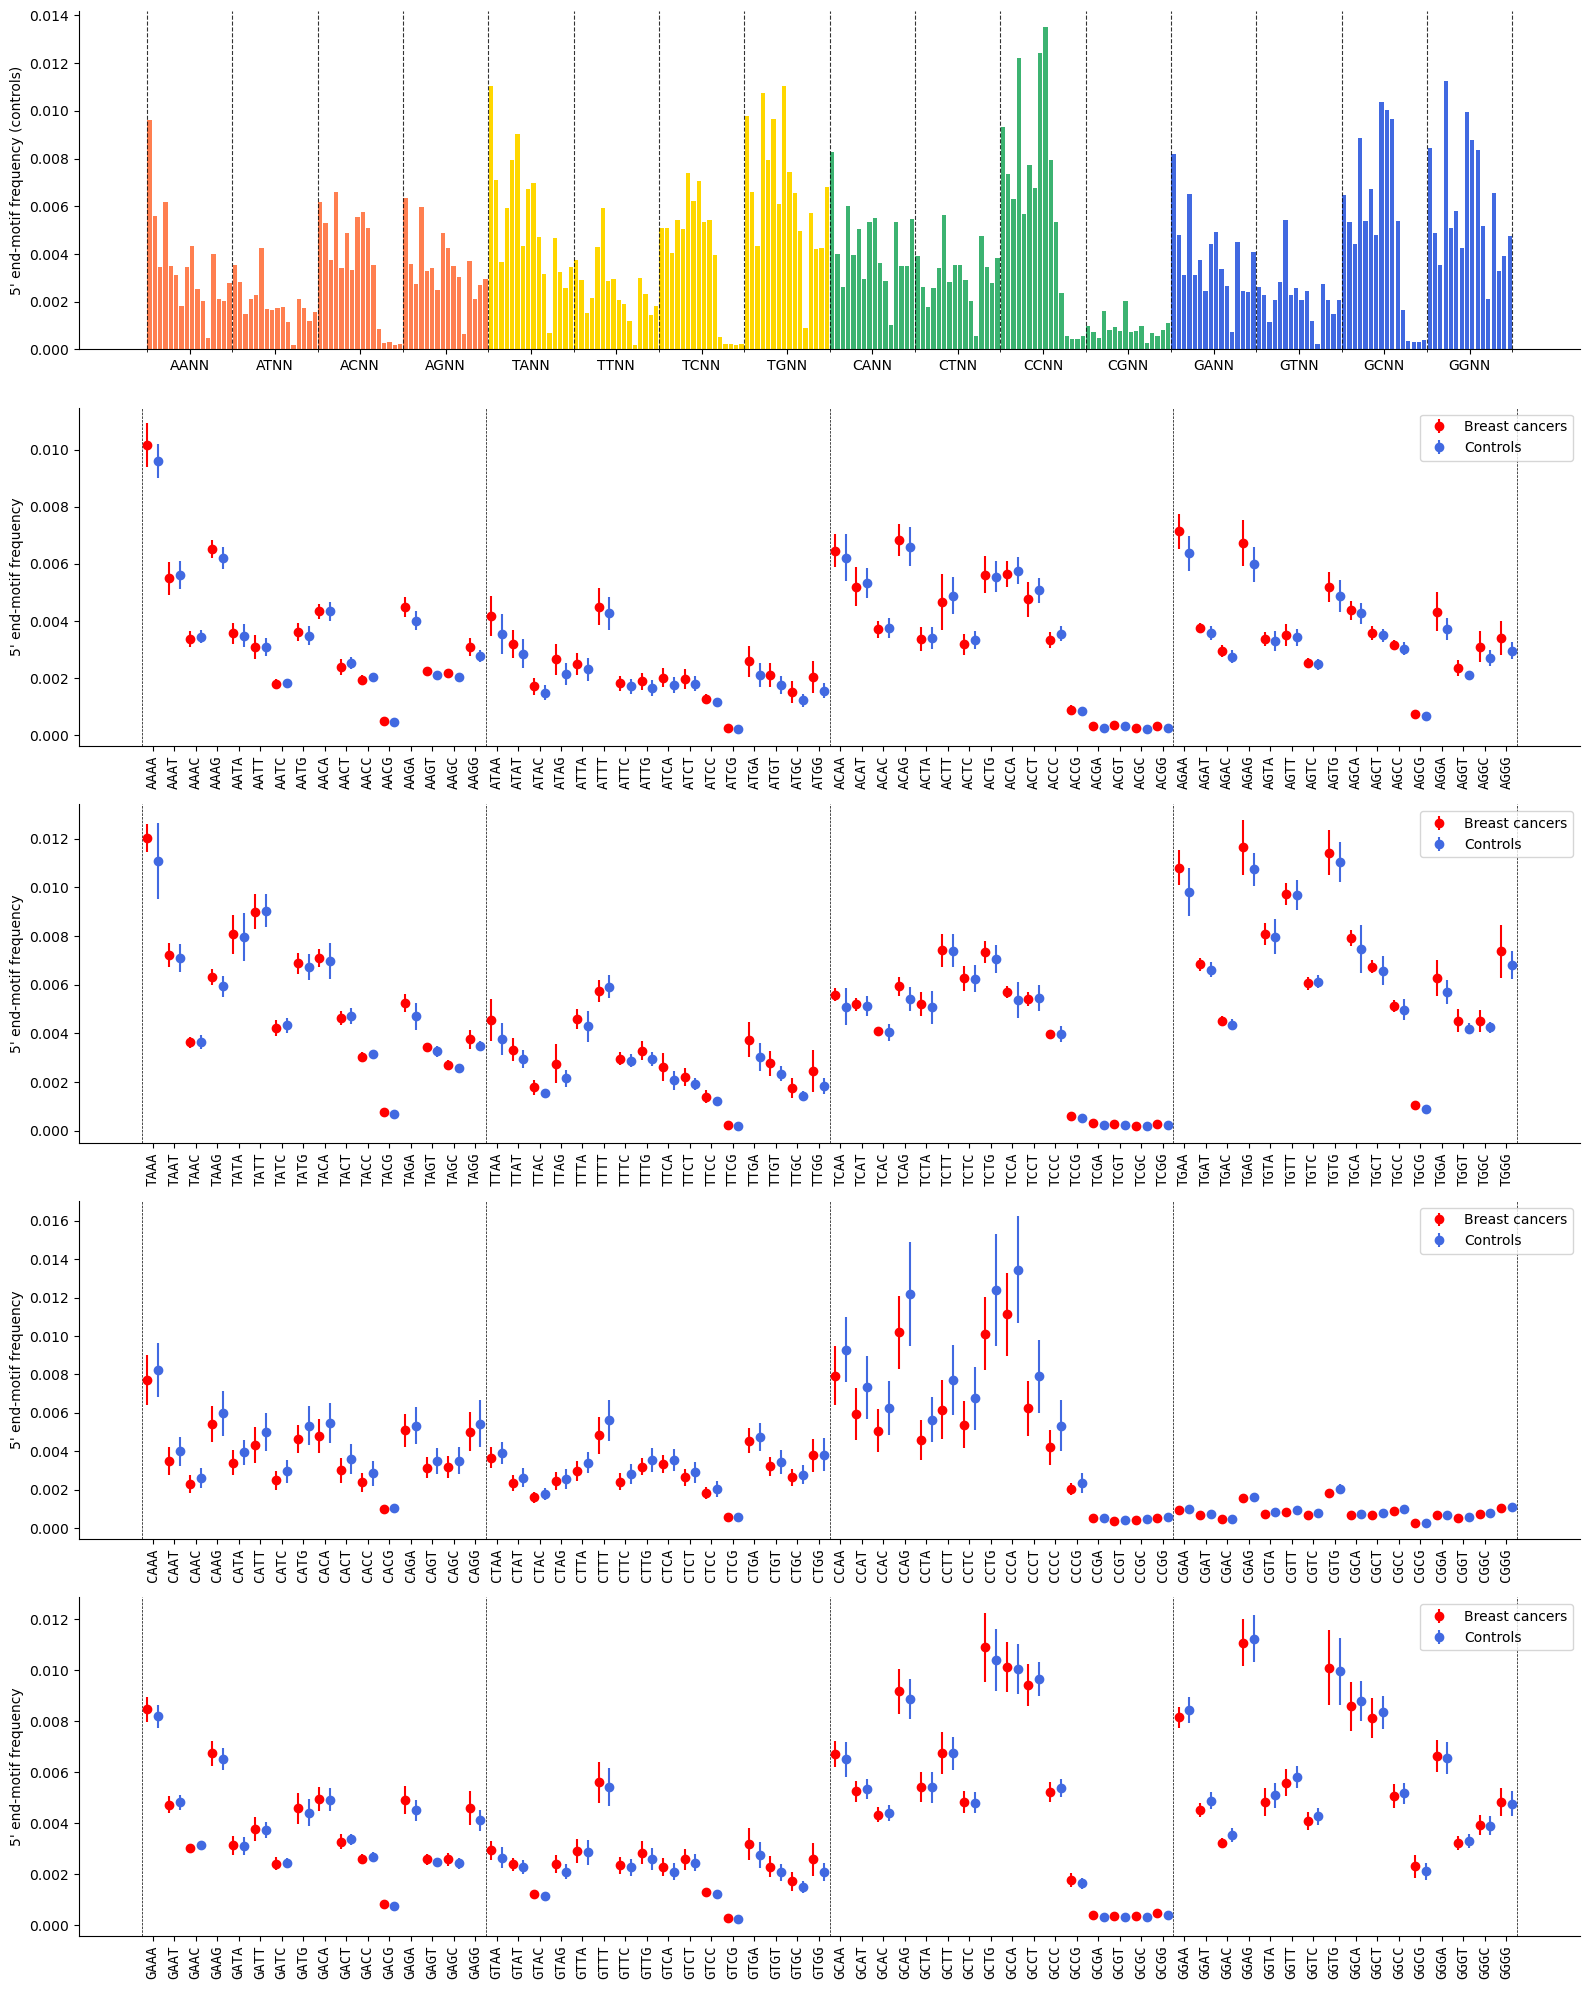

In [22]:
# Get labels (0 for control, 1 for cancer)
y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)

# Compute average end-motif frequencies across controls
X = dataset.data['End-motif probability (5 prime)']
X = X / np.sum(X, axis=1)[:, np.newaxis]
hist1 = np.sum(X[y == 0, :], axis=0)
hist1 = hist1 / np.sum(hist1)

plt.figure(figsize=(16, 20))

# Show average end-motif frequencies across controls
ax = plt.subplot(5, 1, 1)
X = data['End-motif probability (5 prime)']
xs, ys = np.arange(len(hist1)) + 0.5, hist1
plt.bar(xs[:64], ys[:64], color='coral')
plt.bar(xs[64:128], ys[64:128], color='gold')
plt.bar(xs[128:192], ys[128:192], color='mediumseagreen')
plt.bar(xs[192:], ys[192:], color='royalblue')
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.set_xticks(range(0, 257, 16), minor=True)
ax.set_xticklabels(['' for _ in range(17)], minor=True)
ax.set_xticks(np.arange(0, 256, 16) + 8, minor=False)
labels = ['AANN', 'ATNN', 'ACNN', 'AGNN', 'TANN', 'TTNN', 'TCNN', 'TGNN', 'CANN', 'CTNN', 'CCNN', 'CGNN', 'GANN', 'GTNN', 'GCNN', 'GGNN']
ax.set_xticklabels(labels, minor=False)
ax.grid(which='minor', alpha=0.8, linestyle='--', linewidth=0.8, color='black')
plt.axhline(y=0, linestyle='--', color='black', linewidth=0.5)
ax.set_ylabel('5\' end-motif frequency (controls)')

for p in range(4):
    ax = plt.subplot(5, 1, p + 2)

    # Show average end-motif frequencies across cancer cases
    X = data['End-motif probability (5 prime)']
    X = X[y > 0]
    zs = np.std(X / np.sum(X, axis=1)[:, np.newaxis], axis=0)
    hist1 = np.sum(X, axis=0)
    hist1 = hist1 / np.sum(hist1)
    xs, ys = np.arange(len(hist1)), hist1
    xs = xs * 2
    ax.errorbar(xs[:64], ys[p*64:(p+1)*64], zs[p*64:(p+1)*64], fmt='o', color='red', label='Breast cancers')

    # Show average end-motif frequencies across controls
    X = data['End-motif probability (5 prime)']
    X = X[y == 0]
    zs = np.std(X / np.sum(X, axis=1)[:, np.newaxis], axis=0)
    hist2 = np.sum(X, axis=0)
    hist2 = hist2 / np.sum(hist2)
    xs, ys = np.arange(len(hist2)), hist2
    xs = xs * 2 + 1
    ax.errorbar(xs[:64], ys[p*64:(p+1)*64], zs[p*64:(p+1)*64], fmt='o', color='royalblue', label='Controls')

    for side in ['right', 'top']:
        ax.spines[side].set_visible(False)
    ax.grid(which='minor', alpha=0.8, linestyle='--', linewidth=0.8, color='black')
    ax.set_ylabel('5\' end-motif frequency')
    labels = [uint8_motif_to_str(i) for i in range(p*64, (p+1)*64)]
    ax.set_xticks(np.arange(len(labels)) * 2 + 0.5, labels, rotation=90, font='monospace')

    for i in range(5):
        ax.axvline(x=i*32 - 0.5, linestyle='--', color='black', linewidth=0.5)
    
    ax.legend()

plt.tight_layout()
plt.show()

<h1 id="multimodal-heatmap">Multimodal heatmaps</h1> <a class="anchor" id="multimodal-heatmap"></a>

In [30]:
def multimodal_heatmap(dataset: Dataset) -> None:

    # Get labels (0 for control, 1 for cancer)
    y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)
    
    plt.figure(figsize=(20, 7))
    _, ax = plt.subplots(1, 6, width_ratios=[3, 3, 3, 1, 1, 1], figsize=(20, 10), sharey=True)

    # The list of modalities to be displayed
    kwargs = dict(cache=True, probabilistic=True)
    modalities = [
        NucleosomePositioningModality(**kwargs),
        CoverageModality(**kwargs),
        CpGMethylationModality(**kwargs),
        EndMotifFrequencyModality(**kwargs),
        JaggednessModality(**kwargs),
        FragLengthCountModality(**kwargs)
    ]
    xlabels = ['Nucleosome positioning', 'Coverage profile', 'CpG methylation', 'End motifs', 'Jaggedness', 'Fragment lengths']
    
    for p, modality in enumerate(modalities):

        # Compute the features for current modality (pre-processing)
        print(modality)
        X = modality.process(dataset.data)

        # Standardization to help the visualization
        X = RobustScaler().fit(X[y == 0]).transform(X)
        X = np.sign(X) * (np.abs(X) > 2)

        # Re-order X to group samples by cancer stage
        Xs = []
        mask = np.asarray([not annot.is_cancer for annot in dataset.annotations], dtype=bool)
        Xs.append(X[mask, :])
        for stage in [0, 1, 2, 3, 4, -1]:  # All cancer stages (-1 == control)
            mask = np.asarray([annot.is_cancer and (np.nan_to_num(float(annot), nan=-1) == stage) for annot in dataset.annotations], dtype=bool)
            Xs.append(X[mask, :])
        sizes = [len(X) for X in Xs]  # Number of samples for each cancer stage
        X = np.concatenate(Xs, axis=0)

        # Create heatmap
        ax[p].imshow(X, cmap='bwr', aspect='auto', interpolation='none')
        for split in np.cumsum(sizes)[:-1]:
            ax[p].axhline(y=split, linestyle='-', color='black', linewidth=1)
        ax[p].set_title(xlabels[p])
        splits = np.asarray([0] + list(np.cumsum(sizes)))
        splits = 0.5 * (splits[:-1] + splits[1:])
        ax[p].set_yticks(splits)
        ax[p].set_yticklabels(['Healthy controls', '0', 'I', 'II', 'III', 'IV', 'Unknown cancer stage'], rotation=90, fontsize=11)
        for tick in ax[p].yaxis.get_majorticklabels():
            tick.set_verticalalignment('center')
    
    plt.show()

GC-correction: 100%|█████████████████████████████████████████████████████████████████| 354/354 [00:05<00:00, 62.10it/s]


CPG (354, 2233)


Infer beta values:  39%|████████████████████████▏                                     | 39/100 [00:03<00:05, 10.34it/s]


Infer concentration params:   0%|                                                      | 1/500 [00:00<00:05, 90.91it/s]


Infer concentration params:   1%|▌                                                     | 5/500 [00:00<00:06, 73.47it/s]


<Figure size 2000x700 with 0 Axes>

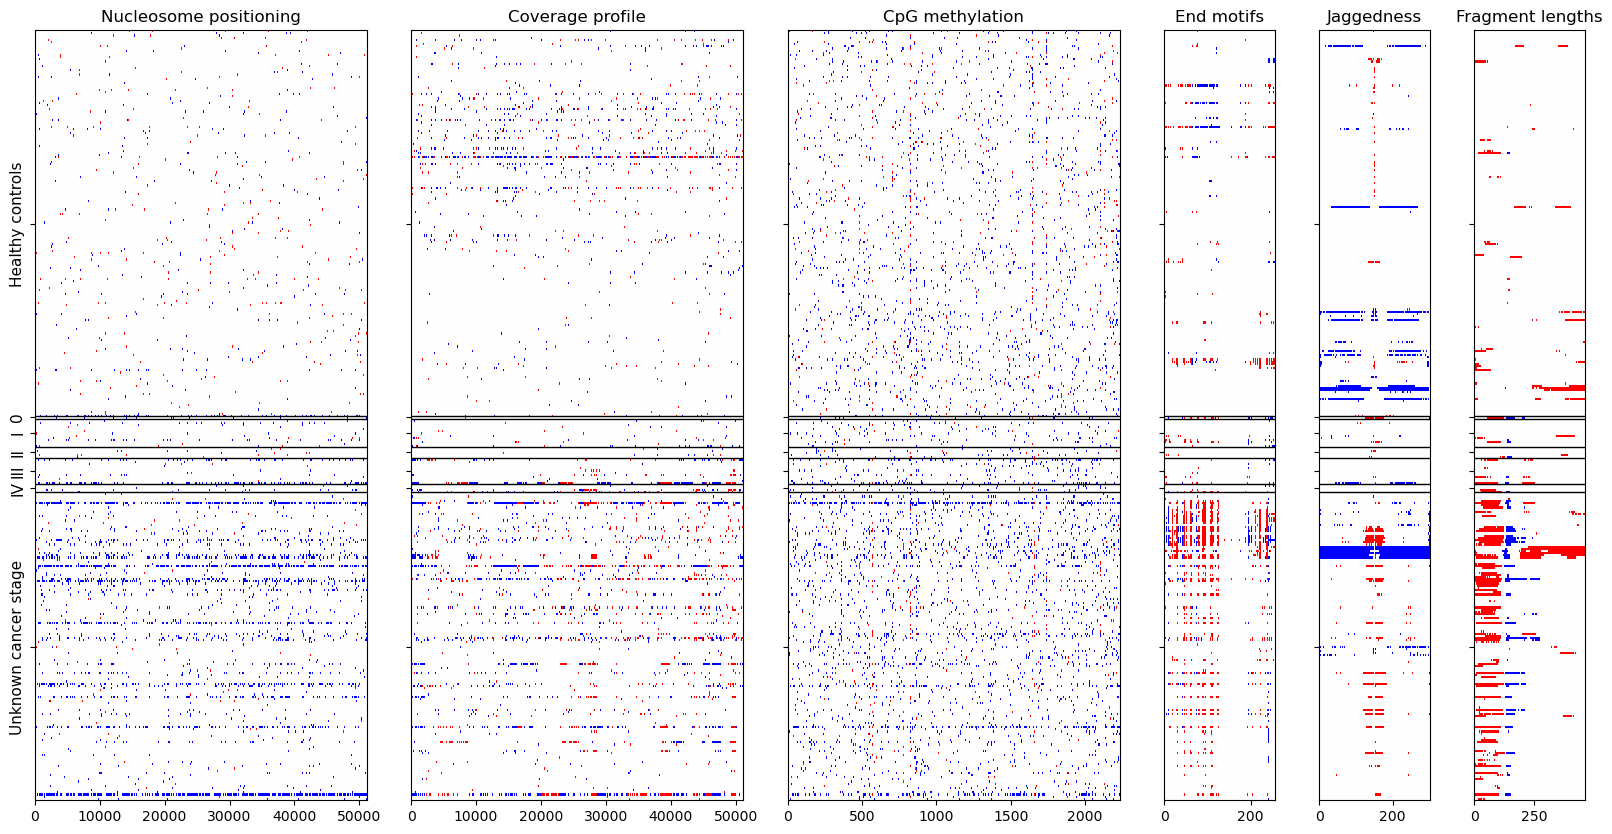

In [31]:
multimodal_heatmap(dataset)
plt.show()

<h1 id="preprocessing">Preprocessing and kernel matrices</h1> <a class="anchor" id="preprocessing"></a>

If you plan to work with the features yourself, you can use one of the following classes: `JaggednessModality`, `EndMotifFrequencyModality`, `CoverageModality`, `CpGMethylationModality`, `NucleosomePositioningModality`, `FragLengthCountModality`, `CellTypeDeconvolutionModality`, `LongFragmentRatioModality`.

For example, let's compute and pre-process the coverage profiles (fragment counting + GC-correction + smoothing + standardization):

In [44]:
modality = CoverageModality()
X = modality.process(dataset.data, fit=True)
print(X[0, :])  # Print profile of first sample
X.shape

GC-correction: 100%|█████████████████████████████████████████████████████████████████| 210/210 [00:02<00:00, 79.47it/s]


[-1.33285443 -0.34016341 -1.1486531  ... -0.97936708 -0.3104977
  0.64611277]


(210, 51149)

If you need the kernel matrix instead, you can do:

In [47]:
K = modality.fit_transform(dataset.data)

# When new data (test set) come in, instead you should call:
#K = modality.transform(dataset.data)
# However, the transform method works only after fitting the modality object at least once.

K.shape

GC-correction: 100%|█████████████████████████████████████████████████████████████████| 210/210 [00:02<00:00, 74.28it/s]


(210, 210)

(210, 210)


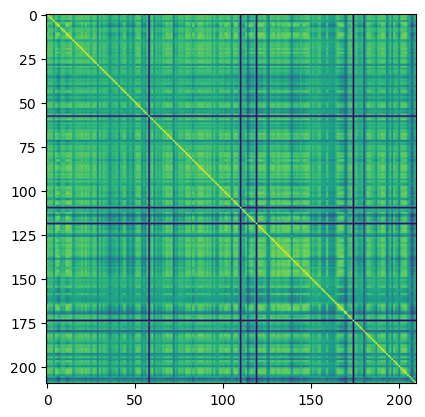

In [48]:
print(K.shape)
plt.imshow(K)
plt.show()

<h1 id="tsne">t-SNE / Kernel PCA</h1> <a class="anchor" id="tsne"></a>

In [33]:
probabilistic = True  # Whether to use probabilistic modeling to correct features for heteroscedasticity (slower)

# List of modalities to be used in the MKL approach
modalities = [Modalities.CELL_TYPE_DECONVOLUTION, Modalities.NUCLEOSOME_POSITIONING, Modalities.LONG_FRAG_RATIO, Modalities.FRAG_LENGTH_COUNTS, Modalities.CPG_METHYLATION, Modalities.COVERAGE, Modalities.JAGGEDNESS, Modalities.END_MOTIFS]

# Pre-processing the features and perform MKL
K = MultipleKernelLearning(modalities, mod_options={'probabilistic': True, 'cache': False}).fit_transform(dataset.data)
K.shape

Infer concentration params:   1%|▌                                                     | 5/500 [00:00<00:05, 84.63it/s]


CPG (354, 2233)


Infer concentration params:   0%|                                                      | 1/500 [00:00<00:05, 90.10it/s]


weights [0.13973620870895126, 0.06952981447085707, 0.13256304394455676, 0.17064150853930732, 0.11091081627043133, 0.07517115205774866, 0.15881134071597214, 0.1426361152921754]


(354, 354)

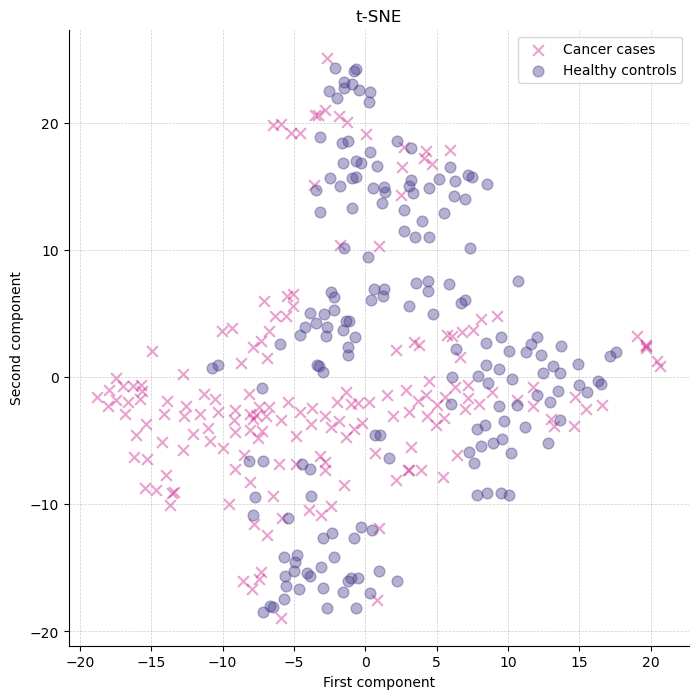

In [35]:
# Get labels (0 for control, 1 for cancer)
y = np.asarray([annot.is_cancer for annot in dataset.annotations], dtype=int)

# Convert kernel matrix to Euclidean distance matrix
D = np.sqrt(np.diagonal(K)[np.newaxis, :] + np.diagonal(K)[:, np.newaxis] - 2 * K)
coords = TSNE(n_components=2, init='random', metric='precomputed').fit_transform(D)
# An alternative is to use kernel PCA:
#coords = KernelPCA(n_components=2, kernel='precomputed').fit_transform(K)

# Make scatter plot out of t-SNE
plt.figure(figsize=(8, 8))
ax = plt.subplot(1, 1, 1)
ax.scatter(coords[y == 1, 0], coords[y == 1, 1], alpha=0.4, s=60, label='Cancer cases', color='mediumvioletred', marker='x')
ax.scatter(coords[y == 0, 0], coords[y == 0, 1], alpha=0.4, s=60, label='Healthy controls', color='darkslateblue')
ax.set_title('t-SNE')
ax.grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax.spines[side].set_visible(False)
ax.set_xlabel('First component')
ax.set_ylabel('Second component')
ax.legend()
plt.show()

<h1 id="supervised-learning">Supervised learning</h1> <a class="anchor" id="supervised-learning"></a>

<h2>Cross-validation on the train data</h2>

In [37]:
dataset = get_dataset(DATASET_TRAIN)

Nucleosomes
weights [1.0]


9it [00:00, 144.11it/s]

(210,) (210,)
Train MCC: 1.0
Train AUROC: 1.0
Train AUPR: 1.0
MCC: 0.25756371316446414
AUROC: 0.67437641723356
AUPR: 0.7599483196470291

Cell type deconvolution



0.6834360361099243: 100%|██████████████████████████████████████████████████████████| 1000/1000 [05:00<00:00,  3.32it/s]


weights [1.0]


9it [00:00, 41.57it/s]


... (24 outputs left out)

weights [0.07853018633974261, 0.1429477172341038, 0.14423595576533876, 0.17431258674220854, 0.08028788955962025, 0.07613381339290948, 0.15656016407490128, 0.14699168689117528]


9it [00:00, 97.46it/s]

(210,) (210,)
Train MCC: 1.0
Train AUROC: 1.0
Train AUPR: 1.0
MCC: 0.6822824053391169
AUROC: 0.9468480725623583
AUPR: 0.9406692624375771




The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


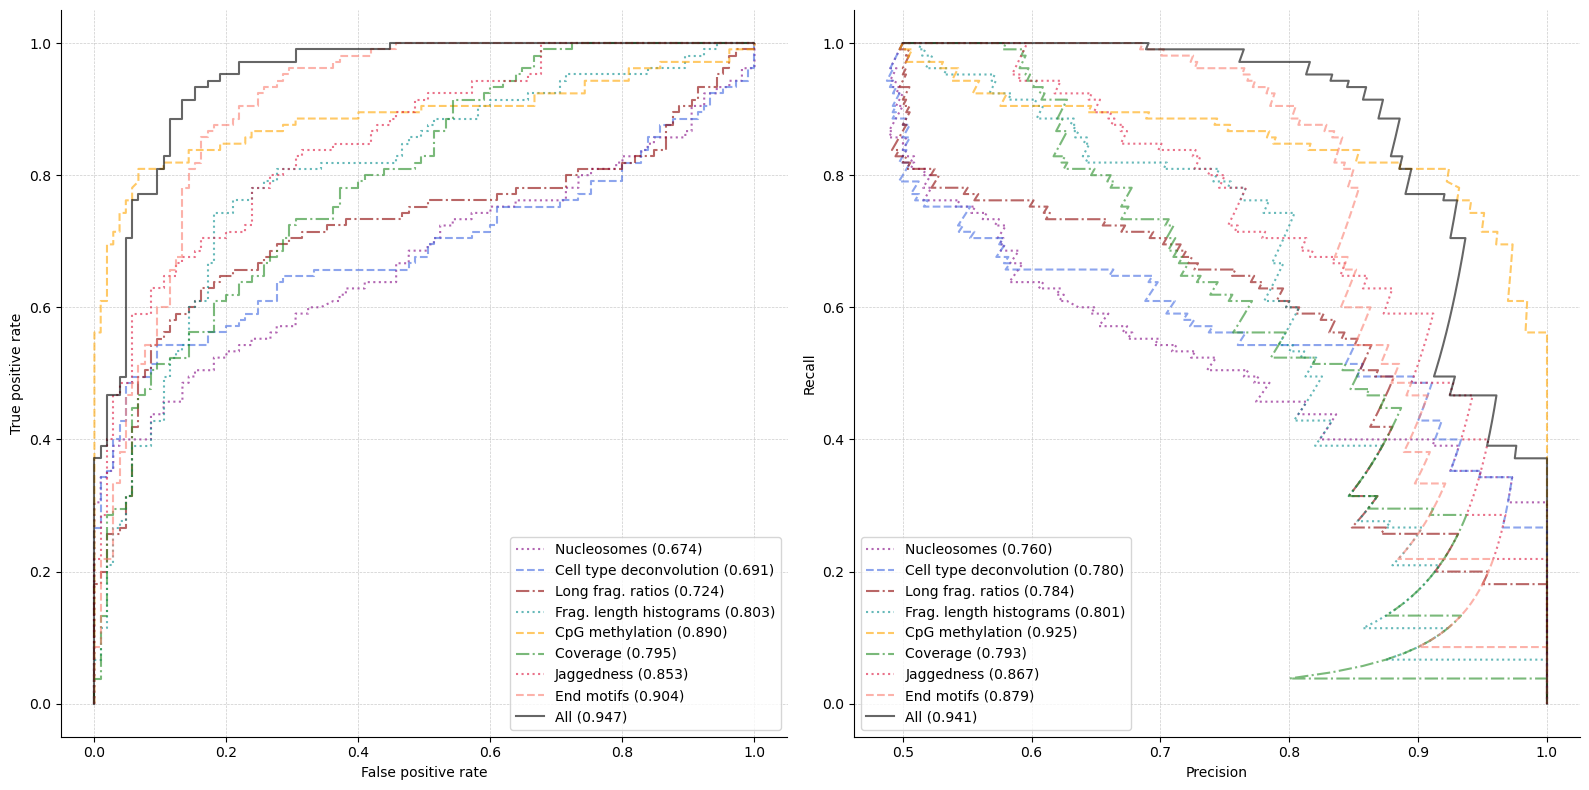

In [39]:
custom_svm = False  # Use multi-stage SVM (much slower)
probabilistic = True  # Whether to use probabilistic modeling to correct features for heteroscedasticity (slower)

# List of settings to experiment with: each modality separately, and finally all modalities combined with MKL
settings = [
    ([Modalities.NUCLEOSOME_POSITIONING], 'Nucleosomes', 'purple', ':'),
    ([Modalities.CELL_TYPE_DECONVOLUTION], 'Cell type deconvolution', 'royalblue', '--'),
    ([Modalities.LONG_FRAG_RATIO], 'Long frag. ratios', 'darkred', '-.'),
    ([Modalities.FRAG_LENGTH_COUNTS], 'Frag. length histograms', 'darkcyan', ':'),
    ([Modalities.CPG_METHYLATION], 'CpG methylation', 'orange', '--'),
    ([Modalities.COVERAGE], 'Coverage', 'forestgreen', '-.'),
    ([Modalities.JAGGEDNESS], 'Jaggedness', 'crimson', ':'),
    ([Modalities.END_MOTIFS], 'End motifs', 'salmon', '--'),
    ([Modalities.NUCLEOSOME_POSITIONING, Modalities.CELL_TYPE_DECONVOLUTION, Modalities.LONG_FRAG_RATIO, Modalities.FRAG_LENGTH_COUNTS, Modalities.CPG_METHYLATION, Modalities.COVERAGE, Modalities.JAGGEDNESS, Modalities.END_MOTIFS], 'All', 'black', '-'),
]

# Iterate over settings
from modalibpy.validation import evaluate
results = []
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
for kernel_idx, label, color, linestyle in settings:
    print(label)

    # Perform leave-one-group-out cross-validation
    res = evaluate(
        dataset,
        kernel_idx,
        custom_svm=custom_svm,
        multi_stage=False,
        mod_options={'probabilistic': probabilistic, 'cache': True}
    )

    # Show ROC and PR curves
    auc, roc, aupr, pr = res['auc'], res['roc'], res['aupr'], res['pr']
    ax[0].plot(roc[0], roc[1], alpha=0.6, label=f'{label} ({auc:.3f})', color=color, linestyle=linestyle)
    ax[1].plot(pr[0], pr[1], alpha=0.6, label=f'{label} ({aupr:.3f})', color=color, linestyle=linestyle)
    results.append(res)

# Show figure
# plt.tight_layout()
ax[0].legend(prop={'size': 10})
ax[1].legend(prop={'size': 10})
ax[0].set_xlabel('False positive rate')
ax[0].set_ylabel('True positive rate')
ax[1].set_xlabel('Precision')
ax[1].set_ylabel('Recall')
#ax[0].set_title('RBF kernel')
#ax[1].set_title('Bias-corrected RBF kernel')
ax[0].grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
ax[1].grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax[0].spines[side].set_visible(False)
    ax[1].spines[side].set_visible(False)
plt.tight_layout()
plt.savefig('perf.eps', dpi=300)
plt.show()

#MCC: 0.4120816918460671
#AUROC: 0.7097270280661284
#AUPR: 0.7353082253168303

## Train on a dataset and predict on another dataset

In [281]:
dataset_train = get_dataset(DATASET_TRAIN)
dataset_test = get_dataset(DATASET_TEST)

All


Infer beta values:   3%|█▉                                                             | 3/100 [00:00<00:03, 26.79it/s]

CPG (210, 2233)


Infer concentration params:   0%|                                                     | 1/500 [00:00<00:02, 166.67it/s]


weights [0.07843098375485597, 0.1428301210666134, 0.14405158105225657, 0.17450772723478755, 0.08029886621702127, 0.07613369637578479, 0.156487331995603, 0.1472596923030774]


GC-correction: 100%|████████████████████████████████████████████████████████████████| 144/144 [00:00<00:00, 186.46it/s]


CPG (144, 2233)


GC-correction: 100%|█████████████████████████████████████████████████████████████████| 144/144 [00:02<00:00, 51.66it/s]
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


MCC: 0.33449275712387466
AUROC: 0.8684413580246914
AUPR: 0.8754363036389382



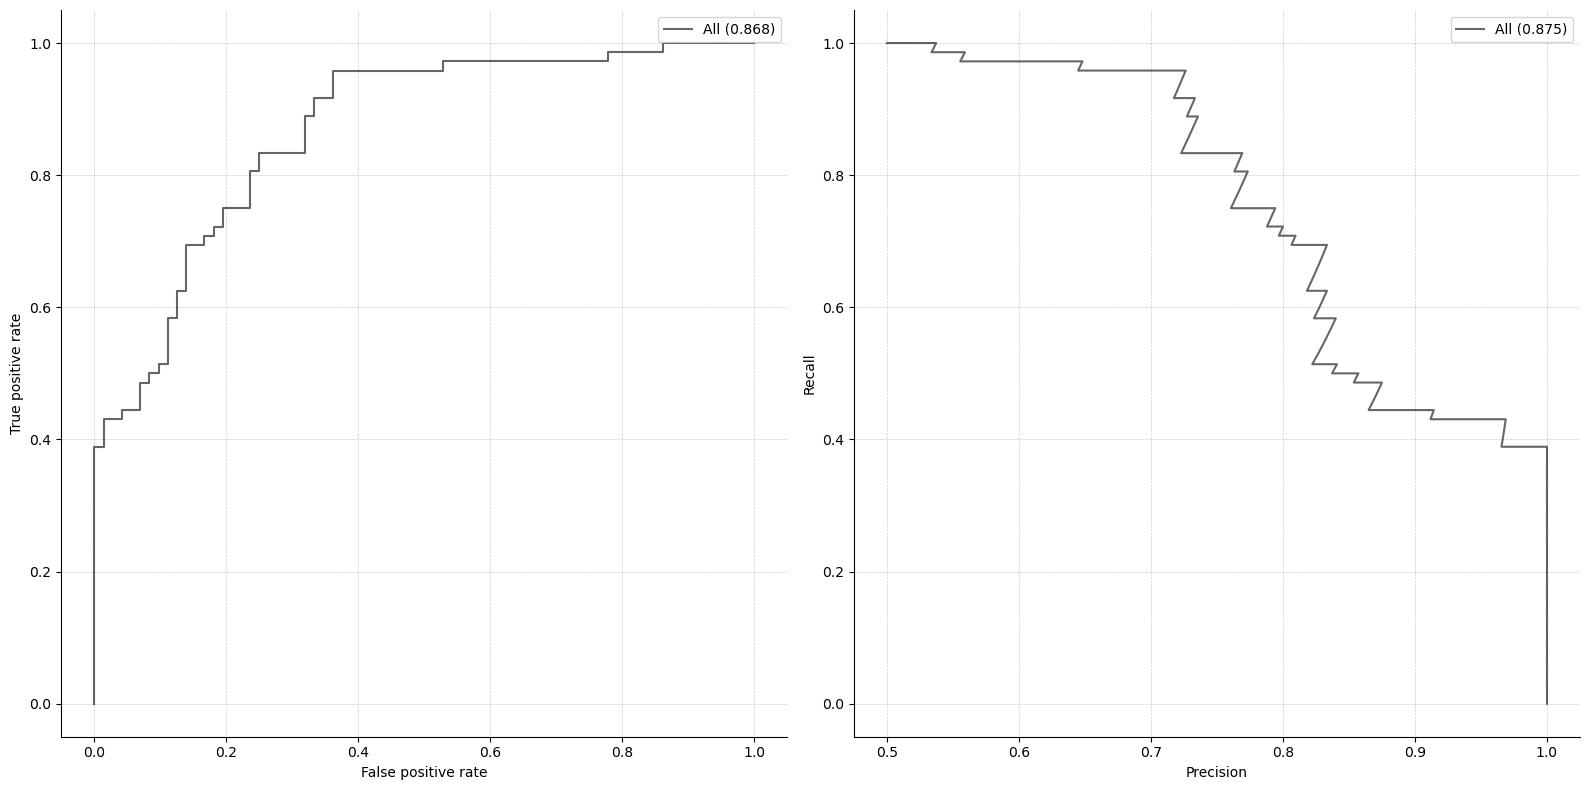

In [283]:
settings = [
    #([Modalities.NUCLEOSOME_POSITIONING], 'Nucleosomes', 'purple', ':'),
    #([Modalities.CELL_TYPE_DECONVOLUTION], 'Cell type deconvolution', 'royalblue', '--'),
    #([Modalities.LONG_FRAG_RATIO], 'Long frag. ratios', 'darkred', '-.'),
    #([Modalities.FRAG_LENGTH_COUNTS], 'Frag. length histograms', 'darkcyan', ':'),
    #([Modalities.CPG_METHYLATION], 'CpG methylation', 'orange', '--'),
    #([Modalities.COVERAGE], 'Coverage', 'forestgreen', '-.'),
    #([Modalities.JAGGEDNESS], 'Jaggedness', 'crimson', ':'),
    ([Modalities.END_MOTIFS], 'End motifs', 'salmon', '--'),
    #([Modalities.NUCLEOSOME_POSITIONING, Modalities.CELL_TYPE_DECONVOLUTION, Modalities.LONG_FRAG_RATIO, Modalities.FRAG_LENGTH_COUNTS, Modalities.CPG_METHYLATION, Modalities.COVERAGE, Modalities.JAGGEDNESS, Modalities.END_MOTIFS], 'All', 'black', '-'),
]

from modalibpy.validation import mkl_train, mkl_validate

fig, ax = plt.subplots(1, 2, figsize=(16, 8))

for kernel_idx, label, color, linestyle in settings:
    print(label)

    # Train pipeline on training set
    mkl, model = mkl_train(
            dataset_train,
            kernel_idx,
            custom_svm=False,
            multi_stage=False,
            regression=False,
            mod_options={'probabilistic': True, 'cache': False}
    )

    # Predict on test set and evaluate performance
    res = mkl_validate(dataset_test, mkl, model, multi_stage=False)

    # Show ROC and PR curves
    auc, roc, aupr, pr = res['auc'], res['roc'], res['aupr'], res['pr']
    ax[0].plot(roc[0], roc[1], alpha=0.6, label=f'{label} ({auc:.3f})', color=color, linestyle=linestyle)
    ax[1].plot(pr[0], pr[1], alpha=0.6, label=f'{label} ({aupr:.3f})', color=color, linestyle=linestyle)

# Show figure
# plt.tight_layout()
ax[0].legend(prop={'size': 10})
ax[1].legend(prop={'size': 10})
ax[0].set_xlabel('False positive rate')
ax[0].set_ylabel('True positive rate')
ax[1].set_xlabel('Precision')
ax[1].set_ylabel('Recall')
#ax[0].set_title('RBF kernel')
#ax[1].set_title('Bias-corrected RBF kernel')
ax[0].grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
ax[1].grid(alpha=0.4, linestyle='--', color='grey', linewidth=0.5)
for side in ['right', 'top']:
    ax[0].spines[side].set_visible(False)
    ax[1].spines[side].set_visible(False)
plt.tight_layout()
plt.savefig('perf.eps', dpi=300)
plt.show()